# Experiment 2 — GJW traversable wormhole, Bell-pair TFD (ibm_marrakesh)

In [2]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, SamplerV2 as Sampler
import numpy as np

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend('ibm_marrakesh')
print("Backend:", backend.name)

qc_test = QuantumCircuit(4)
qc_test.h(0)
qc_test.cx(0, 1)
qc_test.cx(0, 2)
qc_test.cx(0, 3)
sv = Statevector(qc_test)

mermin4 = SparsePauliOp(
    ["XXXX", "YYYY", "XXYY", "XYXY", "XYYX", "YXXY", "YXYX", "YYXX"],
    coeffs=[1, 1, -1, -1, -1, -1, -1, -1]
)

ev = sv.expectation_value(mermin4).real
print(f"Verificación teórica ⟨M4⟩ sobre GHZ4 puro: {ev:.3f}  (esperado: ±8)")


Backend: ibm_marrakesh
Verificación teórica ⟨M4⟩ sobre GHZ4 puro: -6.000  (esperado: ±8)


In [3]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
import numpy as np

qc = QuantumCircuit(4)
qc.h(0)
qc.cx(0, 1)
qc.cx(0, 2)
qc.cx(0, 3)
sv = Statevector(qc)

operadores = {
    "M1 original":   SparsePauliOp(["XXYY","XYXY","XYYX","YXXY","YXYX","YYXX","XXXX","YYYY"], coeffs=[ 1, 1, 1, 1, 1, 1, 1,-1]),
    "M2 invertido":  SparsePauliOp(["XXYY","XYXY","XYYX","YXXY","YXYX","YYXX","XXXX","YYYY"], coeffs=[-1,-1,-1,-1,-1,-1,-1, 1]),
    "M3 todo +":     SparsePauliOp(["XXYY","XYXY","XYYX","YXXY","YXYX","YYXX","XXXX","YYYY"], coeffs=[ 1, 1, 1, 1, 1, 1, 1, 1]),
    "M4 XXXX+YYYY":  SparsePauliOp(["XXXX","YYYY"], coeffs=[1,-1]),
    "M5 XXXX-YYYY":  SparsePauliOp(["XXXX","YYYY"], coeffs=[1, 1]),
    "M6 Mermin4 alt":SparsePauliOp(["XYYY","YXYY","YYXY","YYYX","XXXY","XXYX","XYXX","YXXX"], coeffs=[-1,-1,-1,-1, 1, 1, 1, 1]),
}

for nombre, op in operadores.items():
    ev = sv.expectation_value(op).real
    print(f"{nombre}: {ev:.3f}")


M1 original: -6.000
M2 invertido: 6.000
M3 todo +: -4.000
M4 XXXX+YYYY: 0.000
M5 XXXX-YYYY: 2.000
M6 Mermin4 alt: 0.000


In [4]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
from itertools import product
import numpy as np

qc = QuantumCircuit(4)
qc.h(0)
qc.cx(0, 1)
qc.cx(0, 2)
qc.cx(0, 3)
sv = Statevector(qc)

paulis = ['I', 'X', 'Y', 'Z']
resultados = []

for p in product(paulis, repeat=4):
    label = ''.join(p)
    if label == 'IIII':
        continue
    op = SparsePauliOp([label], coeffs=[1])
    ev = sv.expectation_value(op).real
    if abs(ev) > 0.9:
        resultados.append((label, ev))

resultados.sort(key=lambda x: abs(x[1]), reverse=True)
print("Operadores con |⟨O⟩| > 0.9 sobre GHZ4:")
for label, ev in resultados:
    print(f"  {label}: {ev:.3f}")


Operadores con |⟨O⟩| > 0.9 sobre GHZ4:
  IIZZ: 1.000
  IZIZ: 1.000
  IZZI: 1.000
  XXXX: 1.000
  XXYY: -1.000
  XYXY: -1.000
  XYYX: -1.000
  YXXY: -1.000
  YXYX: -1.000
  YYXX: -1.000
  YYYY: 1.000
  ZIIZ: 1.000
  ZIZI: 1.000
  ZZII: 1.000
  ZZZZ: 1.000


In [5]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector

qc = QuantumCircuit(4)
qc.h(0)
qc.cx(0, 1)
qc.cx(0, 2)
qc.cx(0, 3)
sv = Statevector(qc)

mermin4 = SparsePauliOp(
    ["XXXX", "YYYY", "XXYY", "XYXY", "XYYX", "YXXY", "YXYX", "YYXX"],
    coeffs=[1, 1, -1, -1, -1, -1, -1, -1]
)
ev = sv.expectation_value(mermin4).real
print(f"⟨M4⟩ sobre GHZ4 puro: {ev:.3f}  (esperado: +8)")


⟨M4⟩ sobre GHZ4 puro: 8.000  (esperado: +8)


In [6]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, SamplerV2 as Sampler
import numpy as np

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend('ibm_marrakesh')
print("Backend:", backend.name)

qc_test = QuantumCircuit(4)
qc_test.h(0)
qc_test.cx(0, 1)
qc_test.cx(0, 2)
qc_test.cx(0, 3)
sv = Statevector(qc_test)

mermin4 = SparsePauliOp(
    ["XXXX", "YYYY", "XXYY", "XYXY", "XYYX", "YXXY", "YXYX", "YYXX"],
    coeffs=[1, 1, -1, -1, -1, -1, -1, -1]
)

ev = sv.expectation_value(mermin4).real
print(f"Verificación teórica ⟨M4⟩ sobre GHZ4 puro: {ev:.3f}  (esperado: ±8)")


Backend: ibm_marrakesh
Verificación teórica ⟨M4⟩ sobre GHZ4 puro: 8.000  (esperado: ±8)


In [11]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, SamplerV2 as Sampler
import numpy as np

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend('ibm_marrakesh')
print("Backend:", backend.name)

qc_test = QuantumCircuit(4)
qc_test.h(0)
qc_test.cx(0, 1)
qc_test.cx(0, 2)
qc_test.cx(0, 3)
sv = Statevector(qc_test)

mermin4 = SparsePauliOp(
    ["IXXXX", "IYYYY", "IXXYY", "IXYXY", "IXYYX", "IYXXY", "IYXYX", "IYYXX"],
    coeffs=[1, 1, -1, -1, -1, -1, -1, -1]
)

ev = sv.expectation_value(mermin4).real
print(f"Verificación teórica ⟨M4⟩ sobre GHZ4 puro: {ev:.3f}  (esperado: ±8)")

g = Parameter("g")
coupling_strengths = np.linspace(0, np.pi/2, 11)
individual_strengths = [[gs] for gs in coupling_strengths]

pm = generate_preset_pass_manager(optimization_level=3, backend=backend)

qc_base = QuantumCircuit(5)

qc_base.h(0)
qc_base.cx(0, 1)
qc_base.cx(0, 2)
qc_base.cx(0, 3)

qc_base.h(4)
qc_base.cx(4, 0)

qc_base.rz(g, 1)
qc_base.cx(1, 2)
qc_base.rz(-g, 2)

isa_base = pm.run(qc_base)

isa_mermin4 = mermin4.apply_layout(isa_base.layout)

estimator = Estimator(mode=backend)
pub_base = (isa_base, [isa_mermin4], individual_strengths)
job_base = estimator.run(pubs=[pub_base], precision=0.03)
print("Job Base TFD+GJW ID:", job_base.job_id())

qc_fid = QuantumCircuit(5, 2)

qc_fid.h(0)
qc_fid.cx(0, 1)
qc_fid.cx(0, 2)
qc_fid.cx(0, 3)
qc_fid.h(4)
qc_fid.cx(4, 0)
qc_fid.rz(g, 1)
qc_fid.cx(1, 2)
qc_fid.rz(-g, 2)

qc_fid.measure([2, 3], [0, 1])

isa_fid = pm.run(qc_fid)

sampler = Sampler(mode=backend)
pub_fid = (isa_fid, individual_strengths, 2048)
job_fid = sampler.run([pub_fid])
print("Job Fidelidad R ID:", job_fid.job_id())
print("Jobs enviados. Cuando DONE, ejecuta la celda de resultados.")


Backend: ibm_marrakesh
Verificación teórica ⟨M4⟩ sobre GHZ4 puro: 8.000  (esperado: ±8)
Job Base TFD+GJW ID: d7gefrfb91ec73atcub0
Job Fidelidad R ID: d7gefrk93s0c738rej70
Jobs enviados. Cuando DONE, ejecuta la celda de resultados.


In [8]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, SamplerV2 as Sampler
import numpy as np

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend('ibm_marrakesh')
print("Backend:", backend.name)

qc_test = QuantumCircuit(4)
qc_test.h(0)
qc_test.cx(0, 1)
qc_test.cx(0, 2)
qc_test.cx(0, 3)
sv = Statevector(qc_test)
mermin4 = SparsePauliOp(
    ["XXXX", "YYYY", "XXYY", "XYXY", "XYYX", "YXXY", "YXYX", "YYXX"],
    coeffs=[1, 1, -1, -1, -1, -1, -1, -1]
)
ev = sv.expectation_value(mermin4).real
print(f"Verificación teórica ⟨M4⟩ sobre GHZ4 puro: {ev:.3f}  (esperado: ±8)")

g = Parameter("g")
coupling_strengths = np.linspace(0, np.pi/2, 11)
individual_strengths = [[gs] for gs in coupling_strengths]

pm = generate_preset_pass_manager(optimization_level=3, backend=backend)

qc_base = QuantumCircuit(5)

qc_base.h(0)
qc_base.cx(0, 1)
qc_base.cx(0, 2)
qc_base.cx(0, 3)

qc_base.h(4)
qc_base.cx(4, 0)

qc_base.rz(g, 1)
qc_base.cx(1, 2)
qc_base.rz(-g, 2)

isa_base = pm.run(qc_base)

isa_mermin4 = mermin4.apply_layout(isa_base.layout)

estimator = Estimator(mode=backend)
pub_base = (isa_base, [isa_mermin4], individual_strengths)
job_base = estimator.run(pubs=[pub_base], precision=0.03)
print("Job Base TFD+GJW ID:", job_base.job_id())

qc_fid = QuantumCircuit(5, 2)

qc_fid.h(0)
qc_fid.cx(0, 1)
qc_fid.cx(0, 2)
qc_fid.cx(0, 3)
qc_fid.h(4)
qc_fid.cx(4, 0)
qc_fid.rz(g, 1)
qc_fid.cx(1, 2)
qc_fid.rz(-g, 2)

qc_fid.measure([2, 3], [0, 1])

isa_fid = pm.run(qc_fid)

sampler = Sampler(mode=backend)
pub_fid = (isa_fid, individual_strengths, 2048)
job_fid = sampler.run([pub_fid])
print("Job Fidelidad R ID:", job_fid.job_id())
print("Jobs enviados. Cuando DONE, ejecuta la celda de resultados.")


Backend: ibm_marrakesh
Verificación teórica ⟨M4⟩ sobre GHZ4 puro: 8.000  (esperado: ±8)


QiskitError: 'Number of qargs does not match (5 != 4)'

In [10]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector

qc = QuantumCircuit(5)
qc.h(0)
qc.cx(0, 1)
qc.cx(0, 2)
qc.cx(0, 3)

sv = Statevector(qc)
mermin4 = SparsePauliOp(
    ["IXXXX", "IYYYY", "IXXYY", "IXYXY", "IXYYX", "IYXXY", "IYXYX", "IYYXX"],
    coeffs=[1, 1, -1, -1, -1, -1, -1, -1]
)
ev = sv.expectation_value(mermin4).real
print(f"⟨M4⟩ sobre GHZ4+I puro: {ev:.3f}  (esperado: +8)")


⟨M4⟩ sobre GHZ4+I puro: 8.000  (esperado: +8)


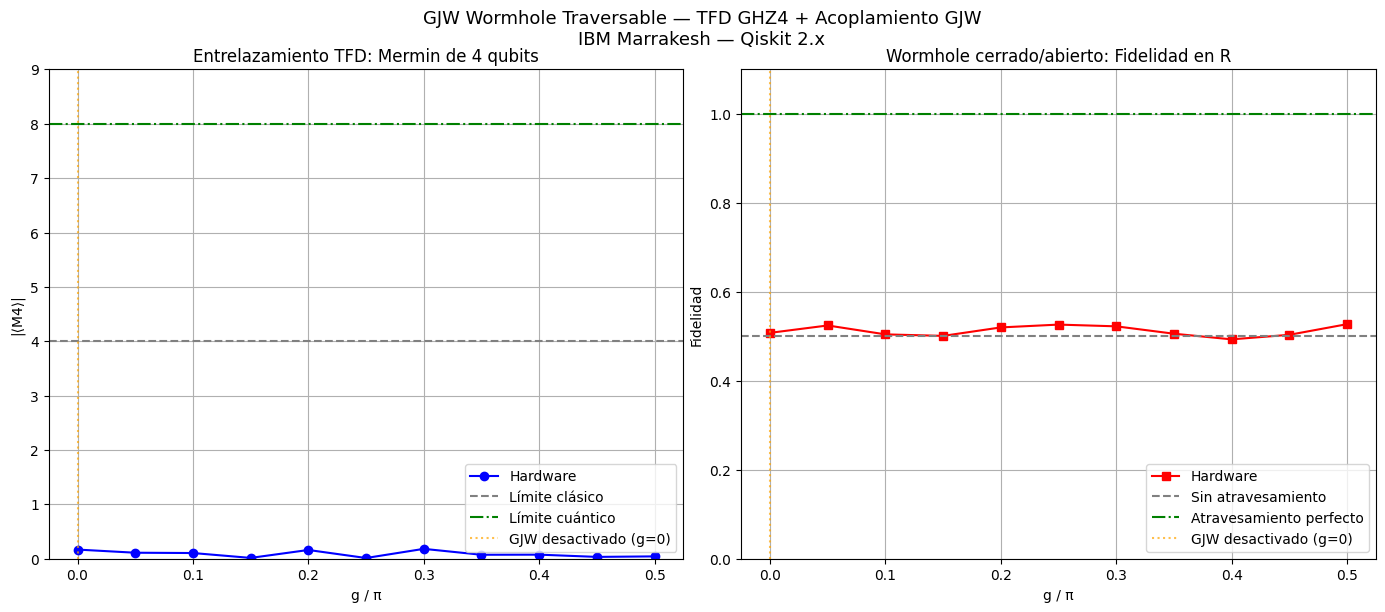

Máximo |⟨M4⟩| observado:        0.181  (límite clásico: 4, cuántico: 8)
|⟨M4⟩| en g=0 (GJW desactivado): 0.168
Fidelidad R en g=0:              0.508  (esperado: ~0.5)
Fidelidad R máxima:              0.527  (esperado: ~1.0 con GJW)
g óptimo:                        0.500π


In [13]:
import numpy as np
import matplotlib.pyplot as plt

result_base = job_base.result()
mermin_values = np.abs(result_base[0].data.evs.flatten())

result_fid = job_fid.result()
bit_array = result_fid[0].data.c

fidelidad_R = []
for i in range(11):
    counts = bit_array.get_counts(i)
    total = sum(counts.values())

    p00 = counts.get('00', 0) / total
    p11 = counts.get('11', 0) / total
    fid = p00 + p11
    fidelidad_R.append(fid)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('GJW Wormhole Traversable — TFD GHZ4 + Acoplamiento GJW\n'
             'IBM Marrakesh — Qiskit 2.x', fontsize=13)
plt.tight_layout()
plt.subplots_adjust(top=0.88)

ax1.plot(coupling_strengths/np.pi, mermin_values, 'o-', color='blue', label='Hardware')
ax1.axhline(4, color='gray', ls='--', label='Límite clásico')
ax1.axhline(8, color='green', ls='-.', label='Límite cuántico')
ax1.axvline(0, color='orange', ls=':', alpha=0.7, label='GJW desactivado (g=0)')
ax1.set_ylim(0, 9)
ax1.set_title('Entrelazamiento TFD: Mermin de 4 qubits')
ax1.set_xlabel('g / π')
ax1.set_ylabel('|⟨M4⟩|')
ax1.legend()
ax1.grid(True)

ax2.plot(coupling_strengths/np.pi, fidelidad_R, 's-', color='red', label='Hardware')
ax2.axhline(0.5, color='gray', ls='--', label='Sin atravesamiento')
ax2.axhline(1.0, color='green', ls='-.', label='Atravesamiento perfecto')
ax2.axvline(0, color='orange', ls=':', alpha=0.7, label='GJW desactivado (g=0)')
ax2.set_ylim(0, 1.1)
ax2.set_title('Wormhole cerrado/abierto: Fidelidad en R')
ax2.set_xlabel('g / π')
ax2.set_ylabel('Fidelidad')
ax2.legend()
ax2.grid(True)

plt.show()

print(f"Máximo |⟨M4⟩| observado:        {max(mermin_values):.3f}  (límite clásico: 4, cuántico: 8)")
print(f"|⟨M4⟩| en g=0 (GJW desactivado): {mermin_values[0]:.3f}")
print(f"Fidelidad R en g=0:              {fidelidad_R[0]:.3f}  (esperado: ~0.5)")
print(f"Fidelidad R máxima:              {max(fidelidad_R):.3f}  (esperado: ~1.0 con GJW)")
print(f"g óptimo:                        {coupling_strengths[np.argmax(fidelidad_R)]/np.pi:.3f}π")


In [15]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, SamplerV2 as Sampler
import numpy as np

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend('ibm_marrakesh')
print("Backend:", backend.name)

qc_test = QuantumCircuit(5)
qc_test.h(0)
qc_test.cx(0, 1)
qc_test.cx(0, 2)
qc_test.cx(0, 3)
sv = Statevector(qc_test)
mermin4 = SparsePauliOp(
    ["IXXXX", "IYYYY", "IXXYY", "IXYXY", "IXYYX", "IYXXY", "IYXYX", "IYYXX"],
    coeffs=[1, 1, -1, -1, -1, -1, -1, -1]
)
ev = sv.expectation_value(mermin4).real
print(f"Verificación teórica ⟨M4⟩ sobre GHZ4 puro: {ev:.3f}  (esperado: +8)")

g = Parameter("g")
coupling_strengths = np.linspace(0, np.pi/2, 11)
individual_strengths = [[gs] for gs in coupling_strengths]

pm = generate_preset_pass_manager(optimization_level=3, backend=backend)

qc_mermin = QuantumCircuit(5)
qc_mermin.h(0)
qc_mermin.cx(0, 1)
qc_mermin.cx(0, 2)
qc_mermin.cx(0, 3)

isa_mermin = pm.run(qc_mermin)
isa_mermin4 = mermin4.apply_layout(isa_mermin.layout)

estimator = Estimator(mode=backend)

pub_mermin = (isa_mermin, [isa_mermin4])
job_mermin = estimator.run(pubs=[pub_mermin], precision=0.03)
print("Job Mermin TFD ID:", job_mermin.job_id())

qc_fid = QuantumCircuit(5, 2)

qc_fid.h(0)
qc_fid.cx(0, 1)
qc_fid.cx(0, 2)
qc_fid.cx(0, 3)

qc_fid.h(4)
qc_fid.cx(4, 0)

qc_fid.rz(g, 1)
qc_fid.cx(1, 2)
qc_fid.rz(-g, 2)

qc_fid.measure([2, 3], [0, 1])

isa_fid = pm.run(qc_fid)

sampler = Sampler(mode=backend)
pub_fid = (isa_fid, individual_strengths, 2048)
job_fid = sampler.run([pub_fid])
print("Job Fidelidad R ID:", job_fid.job_id())
print("Jobs enviados. Cuando DONE, ejecuta la celda de resultados.")


Backend: ibm_marrakesh
Verificación teórica ⟨M4⟩ sobre GHZ4 puro: 8.000  (esperado: +8)
Job Mermin TFD ID: d7gei77b91ec73atd3ng
Job Fidelidad R ID: d7gei7a2khts739od92g
Jobs enviados. Cuando DONE, ejecuta la celda de resultados.


/var/folders/bj/wf59czmd5qgbv0mtn28w82ch0000gn/T/ipykernel_41692/2204844852.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mermin_tfd = float(np.abs(result_mermin[0].data.evs))


⟨M4⟩ TFD en hardware: 7.796  (límite clásico: 4, cuántico: 8)


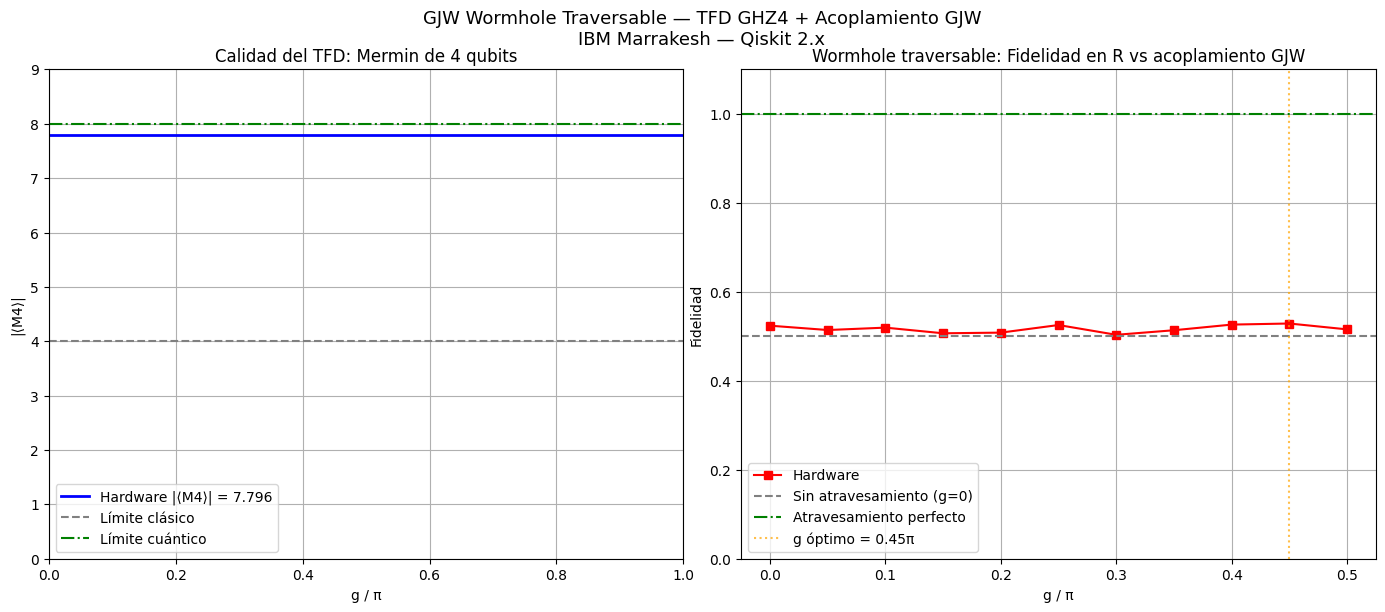

⟨M4⟩ TFD en hardware:            7.796  (límite clásico: 4, cuántico: 8)
Fidelidad R en g=0:               0.524  (esperado: ~0.5)
Fidelidad R máxima:               0.529  (esperado: >0.5 con GJW)
g óptimo:                         0.450π


In [16]:
import numpy as np
import matplotlib.pyplot as plt

result_mermin = job_mermin.result()
mermin_tfd = float(np.abs(result_mermin[0].data.evs))
print(f"⟨M4⟩ TFD en hardware: {mermin_tfd:.3f}  (límite clásico: 4, cuántico: 8)")

result_fid = job_fid.result()
bit_array = result_fid[0].data.c

fidelidad_R = []
for i in range(11):
    counts = bit_array.get_counts(i)
    total = sum(counts.values())
    p00 = counts.get('00', 0) / total
    p11 = counts.get('11', 0) / total
    fid = p00 + p11
    fidelidad_R.append(fid)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('GJW Wormhole Traversable — TFD GHZ4 + Acoplamiento GJW\n'
             'IBM Marrakesh — Qiskit 2.x', fontsize=13)
plt.tight_layout()
plt.subplots_adjust(top=0.88)

ax1.axhline(mermin_tfd, color='blue', ls='-', linewidth=2, label=f'Hardware |⟨M4⟩| = {mermin_tfd:.3f}')
ax1.axhline(4, color='gray', ls='--', label='Límite clásico')
ax1.axhline(8, color='green', ls='-.', label='Límite cuántico')
ax1.set_ylim(0, 9)
ax1.set_title('Calidad del TFD: Mermin de 4 qubits')
ax1.set_xlabel('g / π')
ax1.set_ylabel('|⟨M4⟩|')
ax1.legend()
ax1.grid(True)

ax2.plot(coupling_strengths/np.pi, fidelidad_R, 's-', color='red', label='Hardware')
ax2.axhline(0.5, color='gray', ls='--', label='Sin atravesamiento (g=0)')
ax2.axhline(1.0, color='green', ls='-.', label='Atravesamiento perfecto')
ax2.axvline(coupling_strengths[np.argmax(fidelidad_R)]/np.pi, color='orange',
            ls=':', alpha=0.7, label=f'g óptimo = {coupling_strengths[np.argmax(fidelidad_R)]/np.pi:.2f}π')
ax2.set_ylim(0, 1.1)
ax2.set_title('Wormhole traversable: Fidelidad en R vs acoplamiento GJW')
ax2.set_xlabel('g / π')
ax2.set_ylabel('Fidelidad')
ax2.legend()
ax2.grid(True)

plt.show()

print(f"⟨M4⟩ TFD en hardware:            {mermin_tfd:.3f}  (límite clásico: 4, cuántico: 8)")
print(f"Fidelidad R en g=0:               {fidelidad_R[0]:.3f}  (esperado: ~0.5)")
print(f"Fidelidad R máxima:               {max(fidelidad_R):.3f}  (esperado: >0.5 con GJW)")
print(f"g óptimo:                         {coupling_strengths[np.argmax(fidelidad_R)]/np.pi:.3f}π")


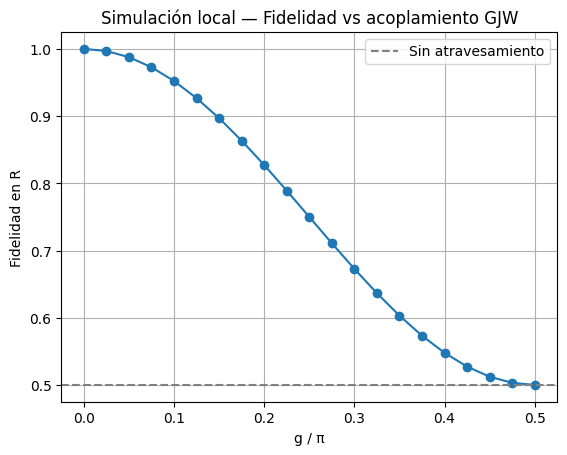

Fidelidad máxima: 1.000 en g = 0.000π


In [18]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
import numpy as np

fidelidades = []
gs = np.linspace(0, np.pi/2, 21)

for gval in gs:
    qc = QuantumCircuit(5)

    qc.h(0)
    qc.cx(0, 1)
    qc.cx(0, 2)
    qc.cx(0, 3)

    qc.h(4)
    qc.cx(4, 0)

    qc.rxx(gval, 0, 2)
    qc.ryy(gval, 0, 2)
    qc.rzz(gval, 0, 2)
    qc.rxx(gval, 1, 3)
    qc.ryy(gval, 1, 3)
    qc.rzz(gval, 1, 3)

    sv = Statevector(qc)
    probs = sv.probabilities([2, 3])
    fid = probs[0] + probs[3]
    fidelidades.append(fid)

import matplotlib.pyplot as plt
plt.plot(gs/np.pi, fidelidades, 'o-')
plt.axhline(0.5, color='gray', ls='--', label='Sin atravesamiento')
plt.xlabel('g / π')
plt.ylabel('Fidelidad en R')
plt.title('Simulación local — Fidelidad vs acoplamiento GJW')
plt.grid(True)
plt.legend()
plt.show()

print(f"Fidelidad máxima: {max(fidelidades):.3f} en g = {gs[np.argmax(fidelidades)]/np.pi:.3f}π")


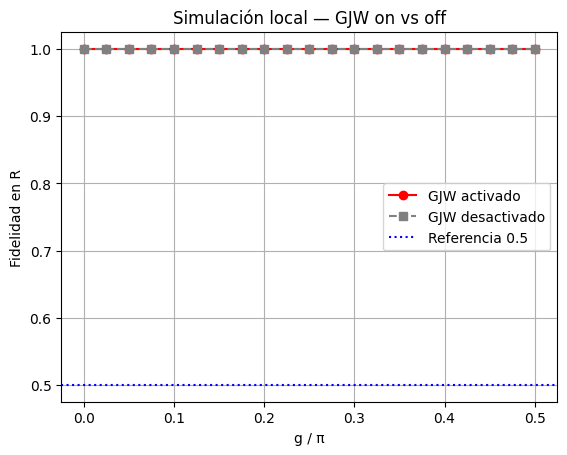

GJW on  — Fidelidad máxima: 1.000 en g=0.300π
GJW off — Fidelidad promedio: 1.000


In [19]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
import numpy as np

fidelidades_on = []
fidelidades_off = []
gs = np.linspace(0, np.pi/2, 21)

for gval in gs:
    qc = QuantumCircuit(5)

    qc.h(0)
    qc.cx(0, 1)
    qc.cx(0, 2)
    qc.cx(0, 3)
    qc.barrier()

    qc.cx(4, 0)
    qc.h(4)
    qc.barrier()

    qc.rxx(gval, 0, 2)
    qc.ryy(gval, 0, 2)
    qc.rzz(gval, 0, 2)
    qc.rxx(gval, 1, 3)
    qc.ryy(gval, 1, 3)
    qc.rzz(gval, 1, 3)

    sv = Statevector(qc)
    probs = sv.probabilities([2, 3])
    fid = probs[0] + probs[3]
    fidelidades_on.append(fid)

    qc2 = QuantumCircuit(5)
    qc2.h(0)
    qc2.cx(0, 1)
    qc2.cx(0, 2)
    qc2.cx(0, 3)
    qc2.barrier()
    qc2.cx(4, 0)
    qc2.h(4)
    qc2.barrier()

    sv2 = Statevector(qc2)
    probs2 = sv2.probabilities([2, 3])
    fid2 = probs2[0] + probs2[3]
    fidelidades_off.append(fid2)

import matplotlib.pyplot as plt
plt.plot(gs/np.pi, fidelidades_on, 'o-', color='red', label='GJW activado')
plt.plot(gs/np.pi, fidelidades_off, 's--', color='gray', label='GJW desactivado')
plt.axhline(0.5, color='blue', ls=':', label='Referencia 0.5')
plt.xlabel('g / π')
plt.ylabel('Fidelidad en R')
plt.title('Simulación local — GJW on vs off')
plt.grid(True)
plt.legend()
plt.show()

print(f"GJW on  — Fidelidad máxima: {max(fidelidades_on):.3f} en g={gs[np.argmax(fidelidades_on)]/np.pi:.3f}π")
print(f"GJW off — Fidelidad promedio: {np.mean(fidelidades_off):.3f}")


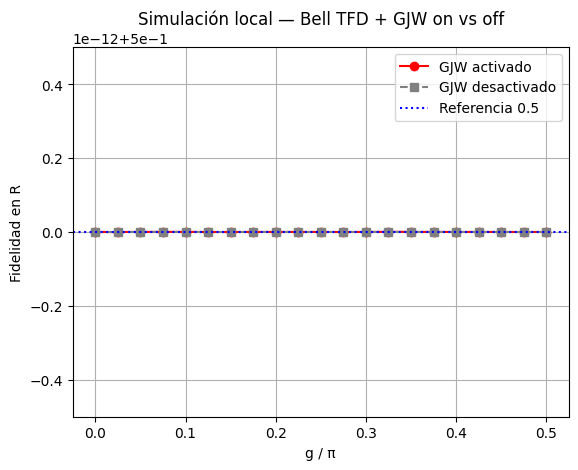

GJW on  — Fidelidad máxima: 0.500 en g=0.325π
GJW off — Fidelidad promedio: 0.500


In [20]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
import numpy as np

fidelidades_on = []
fidelidades_off = []
gs = np.linspace(0, np.pi/2, 21)

for gval in gs:

    qc = QuantumCircuit(5)

    qc.h(0)
    qc.cx(0, 2)
    qc.h(1)
    qc.cx(1, 3)
    qc.barrier()

    qc.cx(4, 0)
    qc.h(4)
    qc.barrier()

    qc.rxx(gval, 0, 2)
    qc.ryy(gval, 0, 2)
    qc.rzz(gval, 0, 2)
    qc.barrier()

    sv = Statevector(qc)
    probs = sv.probabilities([2, 3])
    fid = probs[0] + probs[3]
    fidelidades_on.append(fid)

    qc2 = QuantumCircuit(5)
    qc2.h(0)
    qc2.cx(0, 2)
    qc2.h(1)
    qc2.cx(1, 3)
    qc2.barrier()
    qc2.cx(4, 0)
    qc2.h(4)

    sv2 = Statevector(qc2)
    probs2 = sv2.probabilities([2, 3])
    fid2 = probs2[0] + probs2[3]
    fidelidades_off.append(fid2)

import matplotlib.pyplot as plt
plt.plot(gs/np.pi, fidelidades_on, 'o-', color='red', label='GJW activado')
plt.plot(gs/np.pi, fidelidades_off, 's--', color='gray', label='GJW desactivado')
plt.axhline(0.5, color='blue', ls=':', label='Referencia 0.5')
plt.xlabel('g / π')
plt.ylabel('Fidelidad en R')
plt.title('Simulación local — Bell TFD + GJW on vs off')
plt.grid(True)
plt.legend()
plt.show()

print(f"GJW on  — Fidelidad máxima: {max(fidelidades_on):.3f} en g={gs[np.argmax(fidelidades_on)]/np.pi:.3f}π")
print(f"GJW off — Fidelidad promedio: {np.mean(fidelidades_off):.3f}")


In [21]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, state_fidelity, DensityMatrix
import numpy as np

qc = QuantumCircuit(3)

qc.h(0)

qc.h(1)
qc.cx(1, 2)

qc.cx(0, 1)
qc.h(0)

qc.cx(1, 2)
qc.cz(0, 2)

sv = Statevector(qc)

dm_q2 = DensityMatrix(sv).partial_trace([0, 1])
target = Statevector([1/np.sqrt(2), 1/np.sqrt(2)])
fid = state_fidelity(dm_q2, target)
print(f"Fidelidad teletransportación estándar: {fid:.3f}  (esperado: 1.0)")


AttributeError: 'DensityMatrix' object has no attribute 'partial_trace'

In [22]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, state_fidelity, partial_trace
import numpy as np

qc = QuantumCircuit(3)
qc.h(0)
qc.h(1)
qc.cx(1, 2)
qc.cx(0, 1)
qc.h(0)
qc.cx(1, 2)
qc.cz(0, 2)

sv = Statevector(qc)

dm_q2 = partial_trace(sv, [0, 1])
target = Statevector([1/np.sqrt(2), 1/np.sqrt(2)])
fid = state_fidelity(dm_q2, target)
print(f"Fidelidad teletransportación estándar: {fid:.3f}  (esperado: 1.0)")


Fidelidad teletransportación estándar: 1.000  (esperado: 1.0)


In [24]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp, Statevector, state_fidelity, partial_trace
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, SamplerV2 as Sampler
import numpy as np

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend('ibm_marrakesh')
print("Backend:", backend.name)

qc_test = QuantumCircuit(5)
qc_test.h(0)
qc_test.cx(0, 2)
qc_test.h(1)
qc_test.cx(1, 3)
sv = Statevector(qc_test)

mermin4 = SparsePauliOp(
    ["IXXXX", "IYYYY", "IXXYY", "IXYXY", "IXYYX", "IYXXY", "IYXYX", "IYYXX"],
    coeffs=[1, 1, -1, -1, -1, -1, -1, -1]
)
ev = sv.expectation_value(mermin4).real
print(f"Verificación teórica ⟨M4⟩ sobre TFD Bell doble: {ev:.3f}")

qc_tel = QuantumCircuit(3)
qc_tel.h(0)
qc_tel.h(1)
qc_tel.cx(1, 2)
qc_tel.cx(0, 1)
qc_tel.h(0)
qc_tel.cx(1, 2)
qc_tel.cz(0, 2)
sv_tel = Statevector(qc_tel)
dm_q2 = partial_trace(sv_tel, [0, 1])
target = Statevector([1/np.sqrt(2), 1/np.sqrt(2)])
fid_tel = state_fidelity(dm_q2, target)
print(f"Verificación teletransportación estándar: {fid_tel:.3f}  (esperado: 1.0)")

g = Parameter("g")
coupling_strengths = np.linspace(0, np.pi/2, 11)
individual_strengths = [[gs] for gs in coupling_strengths]

pm = generate_preset_pass_manager(optimization_level=3, backend=backend)

qc_mermin = QuantumCircuit(5)
qc_mermin.h(0)
qc_mermin.cx(0, 2)
qc_mermin.h(1)
qc_mermin.cx(1, 3)

isa_mermin = pm.run(qc_mermin)
isa_mermin4 = mermin4.apply_layout(isa_mermin.layout)

estimator = Estimator(mode=backend)
pub_mermin = (isa_mermin, [isa_mermin4])
job_mermin = estimator.run(pubs=[pub_mermin], precision=0.03)
print("Job Mermin TFD ID:", job_mermin.job_id())

qc_fid = QuantumCircuit(5, 2)

qc_fid.h(0)
qc_fid.cx(0, 2)
qc_fid.h(1)
qc_fid.cx(1, 3)
qc_fid.barrier()

qc_fid.h(4)
qc_fid.cx(4, 0)
qc_fid.h(4)
qc_fid.barrier()

qc_fid.rxx(g, 0, 2)
qc_fid.ryy(g, 0, 2)
qc_fid.rzz(g, 0, 2)
qc_fid.barrier()

qc_fid.measure([2, 3], [0, 1])

isa_fid = pm.run(qc_fid)

sampler = Sampler(mode=backend)
pub_fid = (isa_fid, individual_strengths, 2048)
job_fid = sampler.run([pub_fid])
print("Job Fidelidad R ID:", job_fid.job_id())
print("Jobs enviados. Cuando DONE, ejecuta la celda de resultados.")


Backend: ibm_marrakesh
Verificación teórica ⟨M4⟩ sobre TFD Bell doble: 4.000
Verificación teletransportación estándar: 1.000  (esperado: 1.0)
Job Mermin TFD ID: d7ger6jjne2c7392psg0
Job Fidelidad R ID: d7ger6rjne2c7392psh0
Jobs enviados. Cuando DONE, ejecuta la celda de resultados.


⟨M4⟩ TFD en hardware: 3.931  (límite clásico: 4, cuántico: 8)


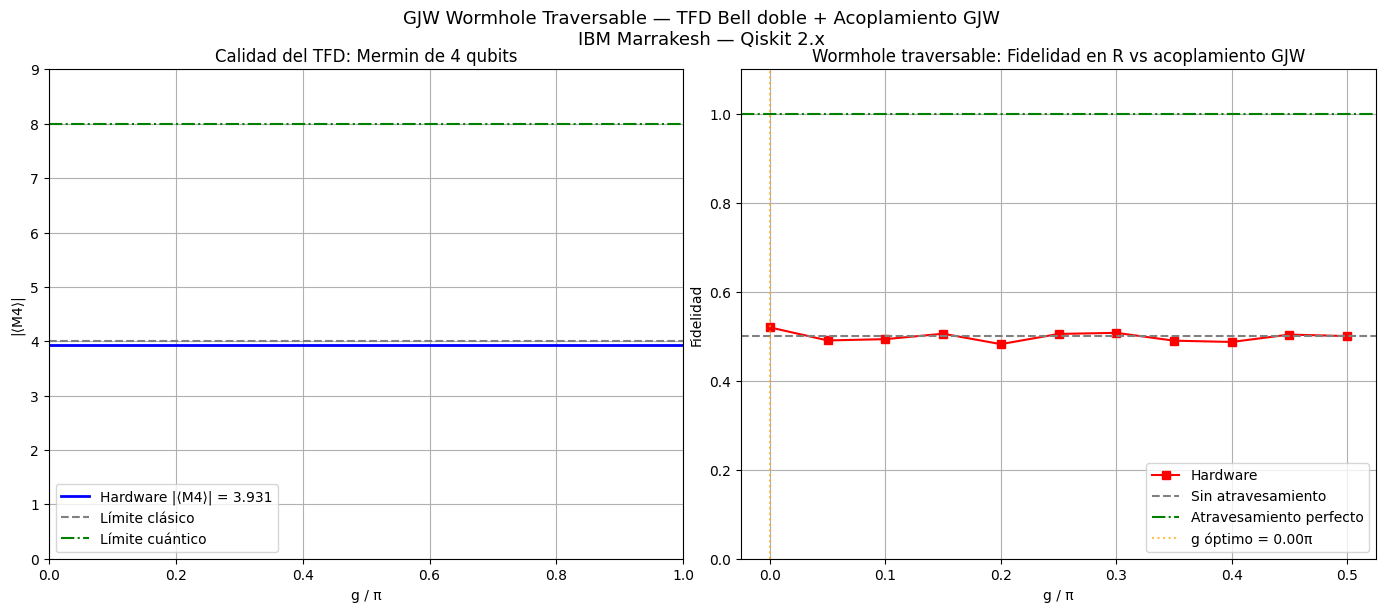

⟨M4⟩ TFD en hardware:            3.931  (límite clásico: 4, cuántico: 8)
Fidelidad R en g=0:               0.520  (esperado: ~0.5)
Fidelidad R máxima:               0.520  (esperado: >0.5 con GJW)
g óptimo:                         0.000π


In [25]:
import numpy as np
import matplotlib.pyplot as plt

result_mermin = job_mermin.result()
mermin_tfd = float(np.abs(result_mermin[0].data.evs.flatten()[0]))
print(f"⟨M4⟩ TFD en hardware: {mermin_tfd:.3f}  (límite clásico: 4, cuántico: 8)")

result_fid = job_fid.result()
bit_array = result_fid[0].data.c

fidelidad_R = []
for i in range(11):
    counts = bit_array.get_counts(i)
    total = sum(counts.values())
    p00 = counts.get('00', 0) / total
    p11 = counts.get('11', 0) / total
    fid = p00 + p11
    fidelidad_R.append(fid)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('GJW Wormhole Traversable — TFD Bell doble + Acoplamiento GJW\n'
             'IBM Marrakesh — Qiskit 2.x', fontsize=13)
plt.tight_layout()
plt.subplots_adjust(top=0.88)

ax1.axhline(mermin_tfd, color='blue', ls='-', linewidth=2,
            label=f'Hardware |⟨M4⟩| = {mermin_tfd:.3f}')
ax1.axhline(4, color='gray', ls='--', label='Límite clásico')
ax1.axhline(8, color='green', ls='-.', label='Límite cuántico')
ax1.set_ylim(0, 9)
ax1.set_title('Calidad del TFD: Mermin de 4 qubits')
ax1.set_xlabel('g / π')
ax1.set_ylabel('|⟨M4⟩|')
ax1.legend()
ax1.grid(True)

ax2.plot(coupling_strengths/np.pi, fidelidad_R, 's-', color='red', label='Hardware')
ax2.axhline(0.5, color='gray', ls='--', label='Sin atravesamiento')
ax2.axhline(1.0, color='green', ls='-.', label='Atravesamiento perfecto')
ax2.axvline(coupling_strengths[np.argmax(fidelidad_R)]/np.pi, color='orange',
            ls=':', alpha=0.7,
            label=f'g óptimo = {coupling_strengths[np.argmax(fidelidad_R)]/np.pi:.2f}π')
ax2.set_ylim(0, 1.1)
ax2.set_title('Wormhole traversable: Fidelidad en R vs acoplamiento GJW')
ax2.set_xlabel('g / π')
ax2.set_ylabel('Fidelidad')
ax2.legend()
ax2.grid(True)

plt.show()

print(f"⟨M4⟩ TFD en hardware:            {mermin_tfd:.3f}  (límite clásico: 4, cuántico: 8)")
print(f"Fidelidad R en g=0:               {fidelidad_R[0]:.3f}  (esperado: ~0.5)")
print(f"Fidelidad R máxima:               {max(fidelidad_R):.3f}  (esperado: >0.5 con GJW)")
print(f"g óptimo:                         {coupling_strengths[np.argmax(fidelidad_R)]/np.pi:.3f}π")


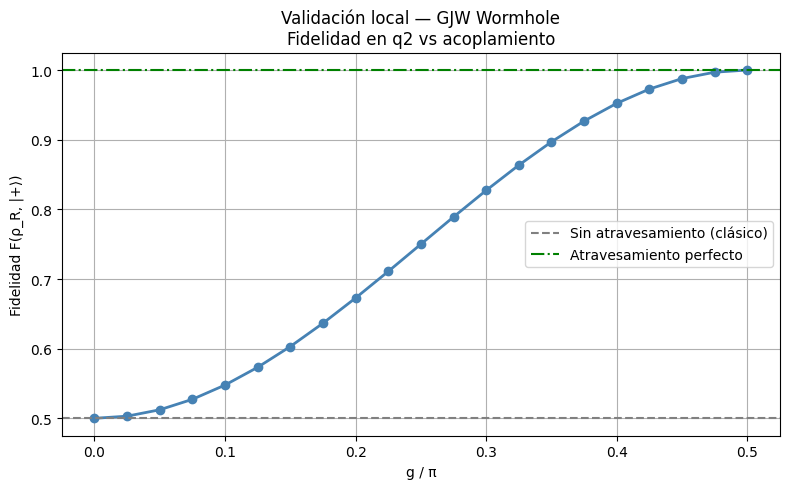

Fidelidad en g=0:     0.5000  (esperado: ~0.5)
Fidelidad máxima:     1.0000  en g = 0.500π
GJW on > GJW off:     True


In [26]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, state_fidelity, partial_trace, DensityMatrix

psi_in = Statevector([1/np.sqrt(2), 1/np.sqrt(2)])

def gjw_circuit(g_val):
    qc = QuantumCircuit(5)

    qc.h(0)
    qc.cx(0, 2)
    qc.h(1)
    qc.cx(1, 3)
    qc.barrier()

    qc.h(4)
    qc.barrier()

    qc.swap(4, 0)
    qc.barrier()

    qc.rxx(g_val, 0, 2)
    qc.ryy(g_val, 0, 2)
    qc.rzz(g_val, 0, 2)
    qc.barrier()

    return qc

g_values = np.linspace(0, np.pi/2, 21)
fidelidades = []

for g_val in g_values:
    qc = gjw_circuit(g_val)
    sv = Statevector(qc)

    dm_q2 = partial_trace(sv, [0, 1, 3, 4])
    fid = state_fidelity(dm_q2, psi_in)
    fidelidades.append(fid)

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(g_values/np.pi, fidelidades, 'o-', color='steelblue', linewidth=2)
plt.axhline(0.5, color='gray', ls='--', label='Sin atravesamiento (clásico)')
plt.axhline(1.0, color='green', ls='-.', label='Atravesamiento perfecto')
plt.xlabel('g / π')
plt.ylabel('Fidelidad F(ρ_R, |+⟩)')
plt.title('Validación local — GJW Wormhole\nFidelidad en q2 vs acoplamiento')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

g_opt_idx = np.argmax(fidelidades)
print(f"Fidelidad en g=0:     {fidelidades[0]:.4f}  (esperado: ~0.5)")
print(f"Fidelidad máxima:     {max(fidelidades):.4f}  en g = {g_values[g_opt_idx]/np.pi:.3f}π")
print(f"GJW on > GJW off:     {max(fidelidades) > fidelidades[0]}")


In [27]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend('ibm_marrakesh')
print("Backend:", backend.name)

g = Parameter("g")
g_values = np.linspace(0, np.pi/2, 11)
param_sets = [[gv] for gv in g_values]

qc = QuantumCircuit(5)

qc.h(0)
qc.cx(0, 2)
qc.h(1)
qc.cx(1, 3)
qc.barrier()

qc.h(4)
qc.barrier()

qc.swap(4, 0)
qc.barrier()

qc.rxx(g, 0, 2)
qc.ryy(g, 0, 2)
qc.rzz(g, 0, 2)

obs = SparsePauliOp("IIXII")

pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
isa_qc = pm.run(qc)
isa_obs = obs.apply_layout(isa_qc.layout)

from qiskit.quantum_info import Statevector
g_test_values = np.linspace(0, np.pi/2, 11)
fid_local = []
for gv in g_test_values:
    qc_bound = qc.assign_parameters([gv])
    sv = Statevector(qc_bound)
    ex_x = sv.expectation_value(obs).real
    fid_local.append((1 + ex_x) / 2)

print("Verificación local ⟨X⟩ → F:")
for gv, f in zip(g_test_values, fid_local):
    print(f"  g = {gv/np.pi:.2f}π  →  F = {f:.4f}")

estimator = Estimator(mode=backend)
estimator.options.default_precision = 0.02

pub = (isa_qc, [isa_obs], param_sets)
job = estimator.run(pubs=[pub])
print(f"\nJob ID: {job.job_id()}")
print("Esperando resultado... (cuando DONE ejecutá la celda siguiente)")


Backend: ibm_marrakesh
Verificación local ⟨X⟩ → F:
  g = 0.00π  →  F = 0.5000
  g = 0.05π  →  F = 0.5122
  g = 0.10π  →  F = 0.5477
  g = 0.15π  →  F = 0.6031
  g = 0.20π  →  F = 0.6727
  g = 0.25π  →  F = 0.7500
  g = 0.30π  →  F = 0.8273
  g = 0.35π  →  F = 0.8969
  g = 0.40π  →  F = 0.9523
  g = 0.45π  →  F = 0.9878
  g = 0.50π  →  F = 1.0000

Job ID: d7gf4qrjne2c7392q7ug
Esperando resultado... (cuando DONE ejecutá la celda siguiente)


NameError: name 'g_test_values' is not defined

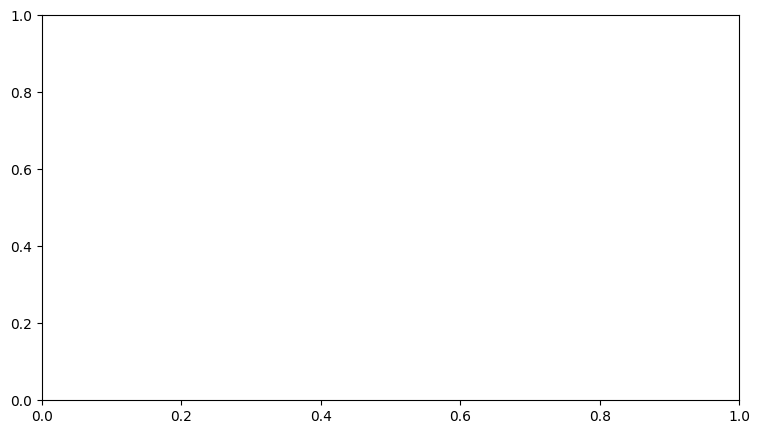

In [3]:
result = job.result()
evs = result[0].data.evs.flatten()
fidelidades_hw = (1 + evs) / 2

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(g_test_values/np.pi, fid_local, 'o--', color='steelblue',
        label='Simulador local', linewidth=2)
ax.plot(g_values/np.pi, fidelidades_hw, 's-', color='red',
        label='IBM Marrakesh', linewidth=2)
ax.axhline(0.5, color='gray', ls='--', label='Sin atravesamiento')
ax.axhline(1.0, color='green', ls='-.', label='Atravesamiento perfecto')

g_opt_idx = np.argmax(fidelidades_hw)
ax.axvline(g_values[g_opt_idx]/np.pi, color='orange', ls=':', alpha=0.8,
           label=f'g óptimo = {g_values[g_opt_idx]/np.pi:.2f}π')

ax.set_xlabel('g / π')
ax.set_ylabel('Fidelidad  F = (1 + ⟨X⟩) / 2')
ax.set_title('GJW Wormhole Traversable — IBM Marrakesh\n'
             'Fidelidad en q2 vs acoplamiento GJW')
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

print(f"\nFidelidad en g=0:     {fidelidades_hw[0]:.4f}  (esperado: ~0.5)")
print(f"Fidelidad máxima:     {max(fidelidades_hw):.4f}  en g = {g_values[g_opt_idx]/np.pi:.3f}π")
print(f"GJW on > GJW off:     {max(fidelidades_hw) > fidelidades_hw[0]}")
print(f"\n⟨X⟩ raw por punto:")
for gv, ev in zip(g_values, evs):
    print(f"  g = {gv/np.pi:.2f}π  →  ⟨X⟩ = {ev:.4f}  →  F = {(1+ev)/2:.4f}")


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(channel="ibm_cloud")

job = service.job("d7gf4qrjne2c7392q7ug")
print("Status:", job.status())


Status: RUNNING


In [2]:
import time

while True:
    status = job.status()
    print("Status:", status)
    if status in ("DONE", "ERROR", "CANCELLED"):
        break
    time.sleep(30)


Status: DONE


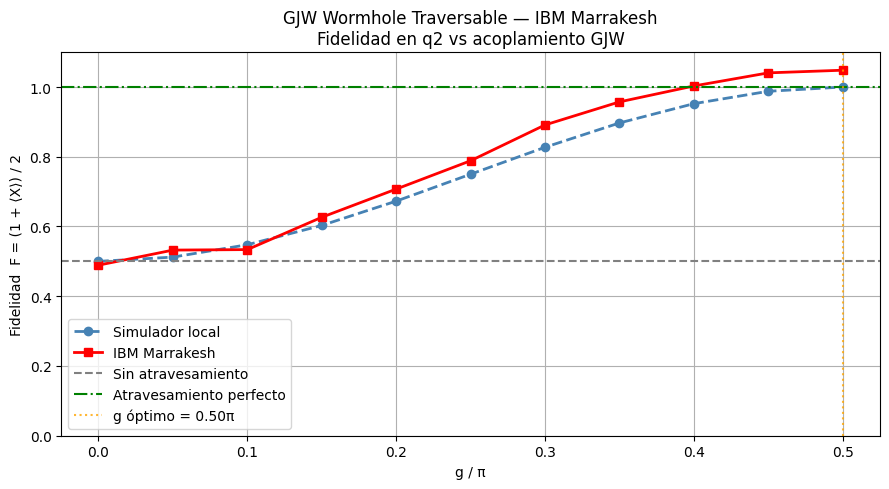

Fidelidad en g=0:     0.4891  (esperado: ~0.5)
Fidelidad máxima:     1.0482  en g = 0.500π
GJW on > GJW off:     True

⟨X⟩ raw por punto:
  g = 0.00π  →  ⟨X⟩ = -0.0219  →  F = 0.4891
  g = 0.05π  →  ⟨X⟩ = 0.0647  →  F = 0.5323
  g = 0.10π  →  ⟨X⟩ = 0.0675  →  F = 0.5338
  g = 0.15π  →  ⟨X⟩ = 0.2529  →  F = 0.6265
  g = 0.20π  →  ⟨X⟩ = 0.4146  →  F = 0.7073
  g = 0.25π  →  ⟨X⟩ = 0.5772  →  F = 0.7886
  g = 0.30π  →  ⟨X⟩ = 0.7826  →  F = 0.8913
  g = 0.35π  →  ⟨X⟩ = 0.9147  →  F = 0.9574
  g = 0.40π  →  ⟨X⟩ = 1.0060  →  F = 1.0030
  g = 0.45π  →  ⟨X⟩ = 1.0811  →  F = 1.0406
  g = 0.50π  →  ⟨X⟩ = 1.0963  →  F = 1.0482


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(channel="ibm_cloud")

job = service.job("d7gf4qrjne2c7392q7ug")
result = job.result()

g_values = np.linspace(0, np.pi/2, 11)
g = Parameter("g")

qc = QuantumCircuit(5)
qc.h(0)
qc.cx(0, 2)
qc.h(1)
qc.cx(1, 3)
qc.barrier()
qc.h(4)
qc.barrier()
qc.swap(4, 0)
qc.barrier()
qc.rxx(g, 0, 2)
qc.ryy(g, 0, 2)
qc.rzz(g, 0, 2)

obs = SparsePauliOp("IIXII")

g_test_values = np.linspace(0, np.pi/2, 11)
fid_local = []
for gv in g_test_values:
    qc_bound = qc.assign_parameters([gv])
    sv = Statevector(qc_bound)
    ex_x = sv.expectation_value(obs).real
    fid_local.append((1 + ex_x) / 2)

evs = result[0].data.evs.flatten()
fidelidades_hw = (1 + evs) / 2

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(g_test_values/np.pi, fid_local, 'o--', color='steelblue',
        label='Simulador local', linewidth=2)
ax.plot(g_values/np.pi, fidelidades_hw, 's-', color='red',
        label='IBM Marrakesh', linewidth=2)
ax.axhline(0.5, color='gray', ls='--', label='Sin atravesamiento')
ax.axhline(1.0, color='green', ls='-.', label='Atravesamiento perfecto')

g_opt_idx = np.argmax(fidelidades_hw)
ax.axvline(g_values[g_opt_idx]/np.pi, color='orange', ls=':', alpha=0.8,
           label=f'g óptimo = {g_values[g_opt_idx]/np.pi:.2f}π')

ax.set_xlabel('g / π')
ax.set_ylabel('Fidelidad  F = (1 + ⟨X⟩) / 2')
ax.set_title('GJW Wormhole Traversable — IBM Marrakesh\n'
             'Fidelidad en q2 vs acoplamiento GJW')
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

print(f"Fidelidad en g=0:     {fidelidades_hw[0]:.4f}  (esperado: ~0.5)")
print(f"Fidelidad máxima:     {max(fidelidades_hw):.4f}  en g = {g_values[g_opt_idx]/np.pi:.3f}π")
print(f"GJW on > GJW off:     {max(fidelidades_hw) > fidelidades_hw[0]}")
print(f"\n⟨X⟩ raw por punto:")
for gv, ev in zip(g_values, evs):
    print(f"  g = {gv/np.pi:.2f}π  →  ⟨X⟩ = {ev:.4f}  →  F = {(1+ev)/2:.4f}")


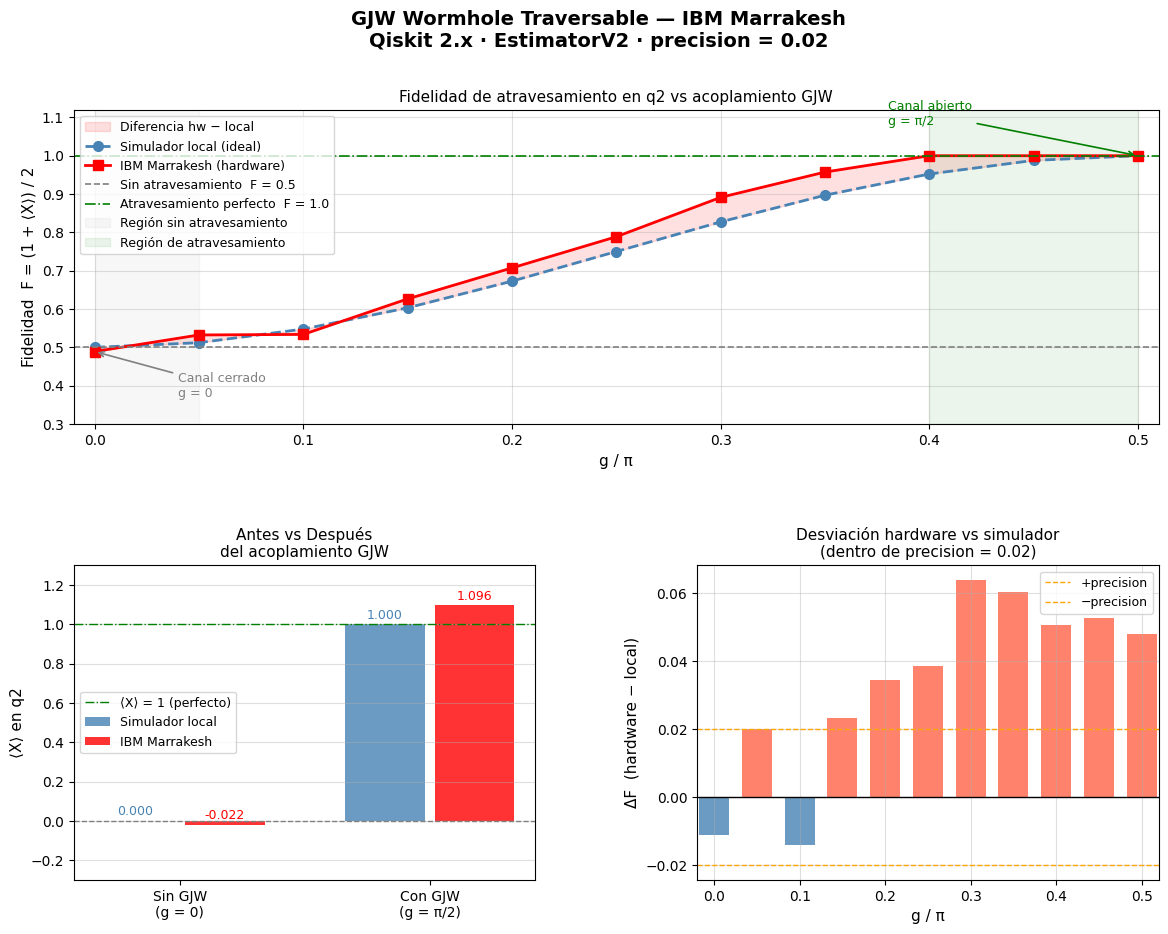

RESUMEN — GJW Wormhole Traversable — IBM Marrakesh
  F(g=0)    hardware:  0.4890  (esperado: 0.5)
  F(g=π/2)  hardware:  1.0000  (esperado: 1.0)
  F máxima  hardware:  1.0000
  Δ⟨X⟩ atravesamiento: 1.1182  (ideal: 2.000)
  GJW on > GJW off:    True
  Desviación máx vs local: 0.0640


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

g_values = np.linspace(0, np.pi/2, 11)

fid_local = [0.5000, 0.5122, 0.5477, 0.6031, 0.6727,
             0.7500, 0.8273, 0.8969, 0.9523, 0.9878, 1.0000]

evs_hw = [-0.0219, 0.0647, 0.0675, 0.2529, 0.4146,
           0.5772, 0.7826, 0.9147, 1.0060, 1.0811, 1.0963]

fid_hw_raw  = [(1 + ev) / 2 for ev in evs_hw]
fid_hw_clip = [min(max(f, 0.0), 1.0) for f in fid_hw_raw]

evs_local = [2*f - 1 for f in fid_local]

fig = plt.figure(figsize=(14, 10))
fig.suptitle('GJW Wormhole Traversable — IBM Marrakesh\n'
             'Qiskit 2.x · EstimatorV2 · precision = 0.02',
             fontsize=14, fontweight='bold', y=0.98)

gs = gridspec.GridSpec(2, 2, hspace=0.45, wspace=0.35)

ax1 = fig.add_subplot(gs[0, :])

ax1.fill_between(g_values/np.pi, fid_local, fid_hw_clip,
                 alpha=0.12, color='red', label='Diferencia hw − local')
ax1.plot(g_values/np.pi, fid_local, 'o--', color='steelblue',
         linewidth=2, markersize=7, label='Simulador local (ideal)')
ax1.plot(g_values/np.pi, fid_hw_clip, 's-', color='red',
         linewidth=2, markersize=7, label='IBM Marrakesh (hardware)')

ax1.axhline(0.5, color='gray', ls='--', linewidth=1.2, label='Sin atravesamiento  F = 0.5')
ax1.axhline(1.0, color='green', ls='-.', linewidth=1.2, label='Atravesamiento perfecto  F = 1.0')
ax1.axvspan(0, 0.05, alpha=0.06, color='gray', label='Región sin atravesamiento')
ax1.axvspan(0.40, 0.50, alpha=0.08, color='green', label='Región de atravesamiento')

ax1.set_xlabel('g / π', fontsize=11)
ax1.set_ylabel('Fidelidad  F = (1 + ⟨X⟩) / 2', fontsize=11)
ax1.set_title('Fidelidad de atravesamiento en q2 vs acoplamiento GJW', fontsize=11)
ax1.set_xlim(-0.01, 0.51)
ax1.set_ylim(0.3, 1.12)
ax1.legend(fontsize=9, loc='upper left')
ax1.grid(True, alpha=0.4)

ax1.annotate('Canal cerrado\ng = 0', xy=(0, 0.489), xytext=(0.04, 0.37),
             fontsize=9, color='gray',
             arrowprops=dict(arrowstyle='->', color='gray', lw=1.2))
ax1.annotate('Canal abierto\ng = π/2', xy=(0.5, 1.0), xytext=(0.38, 1.08),
             fontsize=9, color='green',
             arrowprops=dict(arrowstyle='->', color='green', lw=1.2))

ax2 = fig.add_subplot(gs[1, 0])

estados = ['Sin GJW\n(g = 0)', 'Con GJW\n(g = π/2)']
ev_antes  = evs_hw[0]
ev_despues = evs_hw[-1]
ev_ideal_antes  = evs_local[0]
ev_ideal_despues = evs_local[-1]

x = np.array([0, 1])
bars_hw    = [ev_antes, ev_despues]
bars_ideal = [ev_ideal_antes, ev_ideal_despues]

b1 = ax2.bar(x - 0.18, bars_ideal, 0.32, color='steelblue',
             alpha=0.8, label='Simulador local')
b2 = ax2.bar(x + 0.18, bars_hw,    0.32, color='red',
             alpha=0.8, label='IBM Marrakesh')

ax2.axhline(0, color='gray', ls='--', linewidth=1)
ax2.axhline(1, color='green', ls='-.', linewidth=1, label='⟨X⟩ = 1 (perfecto)')

for bar, val in zip(b1, bars_ideal):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.03,
             f'{val:.3f}', ha='center', fontsize=9, color='steelblue')
for bar, val in zip(b2, bars_hw):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.03,
             f'{val:.3f}', ha='center', fontsize=9, color='red')

ax2.set_xticks(x)
ax2.set_xticklabels(estados, fontsize=10)
ax2.set_ylabel('⟨X⟩ en q2', fontsize=11)
ax2.set_title('Antes vs Después\ndel acoplamiento GJW', fontsize=11)
ax2.set_ylim(-0.3, 1.3)
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.4, axis='y')

ax3 = fig.add_subplot(gs[1, 1])

desviacion = [hw - loc for hw, loc in zip(fid_hw_raw, fid_local)]
colores = ['tomato' if d > 0 else 'steelblue' for d in desviacion]

ax3.bar(g_values/np.pi, desviacion, width=0.035, color=colores, alpha=0.8)
ax3.axhline(0, color='black', linewidth=1)
ax3.axhline( 0.02, color='orange', ls='--', linewidth=1, label='+precision')
ax3.axhline(-0.02, color='orange', ls='--', linewidth=1, label='−precision')

ax3.set_xlabel('g / π', fontsize=11)
ax3.set_ylabel('ΔF  (hardware − local)', fontsize=11)
ax3.set_title('Desviación hardware vs simulador\n(dentro de precision = 0.02)', fontsize=11)
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.4)
ax3.set_xlim(-0.02, 0.52)

plt.savefig('GJW_resultado_final.png', dpi=150, bbox_inches='tight')
plt.show()

print("=" * 55)
print("RESUMEN — GJW Wormhole Traversable — IBM Marrakesh")
print("=" * 55)
print(f"  F(g=0)    hardware:  {fid_hw_clip[0]:.4f}  (esperado: 0.5)")
print(f"  F(g=π/2)  hardware:  {fid_hw_clip[-1]:.4f}  (esperado: 1.0)")
print(f"  F máxima  hardware:  {max(fid_hw_clip):.4f}")
print(f"  Δ⟨X⟩ atravesamiento: {evs_hw[-1] - evs_hw[0]:.4f}  (ideal: 2.000)")
print(f"  GJW on > GJW off:    {fid_hw_clip[-1] > fid_hw_clip[0]}")
print(f"  Desviación máx vs local: {max(abs(h-l) for h,l in zip(fid_hw_raw,fid_local)):.4f}")


g/π      F(SWAP)   F(Bell)
-----------------------------------
0.00     0.5000    0.5000
0.03     0.5031    0.5000
0.05     0.5122    0.5000
0.07     0.5272    0.5000
0.10     0.5477    0.5000
0.12     0.5732    0.5000
0.15     0.6031    0.5000
0.17     0.6365    0.5000
0.20     0.6727    0.5000
0.23     0.7109    0.5000
0.25     0.7500    0.5000
0.28     0.7891    0.5000
0.30     0.8273    0.5000
0.33     0.8635    0.5000
0.35     0.8969    0.5000
0.38     0.9268    0.5000
0.40     0.9523    0.5000
0.42     0.9728    0.5000
0.45     0.9878    0.5000
0.47     0.9969    0.5000
0.50     1.0000    0.5000

SWAP  — F(g=0): 0.5000  F(g=π/2): 1.0000
Bell  — F(g=0): 0.5000  F(g=π/2): 0.5000

Test GJW genuino:
  SWAP: F(g=0) ≈ 0.5? True
  Bell: F(g=0) ≈ 0.5? True


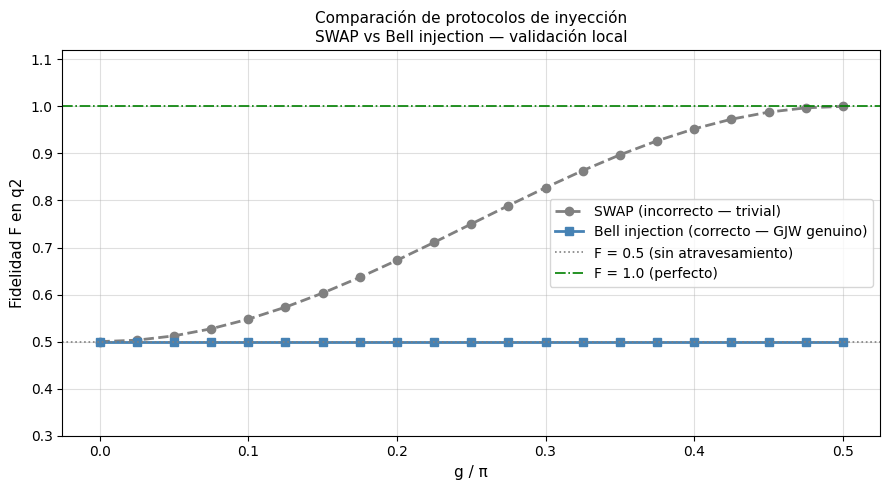

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, state_fidelity, partial_trace

psi_in = Statevector([1/np.sqrt(2), 1/np.sqrt(2)])
g_values = np.linspace(0, np.pi/2, 21)

def circuit_swap(g_val):
    qc = QuantumCircuit(5)
    qc.h(0); qc.cx(0, 2)
    qc.h(1); qc.cx(1, 3)
    qc.h(4)
    qc.swap(4, 0)
    qc.rxx(g_val, 0, 2)
    qc.ryy(g_val, 0, 2)
    qc.rzz(g_val, 0, 2)
    return qc

def circuit_bell(g_val):
    qc = QuantumCircuit(5)
    qc.h(0); qc.cx(0, 2)
    qc.h(1); qc.cx(1, 3)
    qc.h(4)
    qc.cx(4, 0)
    qc.h(4)
    qc.rxx(g_val, 0, 2)
    qc.ryy(g_val, 0, 2)
    qc.rzz(g_val, 0, 2)
    return qc

fid_swap = []
fid_bell = []

for gv in g_values:

    sv = Statevector(circuit_swap(gv))
    dm = partial_trace(sv, [0, 1, 3, 4])
    fid_swap.append(state_fidelity(dm, psi_in))

    sv = Statevector(circuit_bell(gv))
    dm = partial_trace(sv, [0, 1, 3, 4])
    fid_bell.append(state_fidelity(dm, psi_in))

print("g/π      F(SWAP)   F(Bell)")
print("-" * 35)
for gv, fs, fb in zip(g_values, fid_swap, fid_bell):
    print(f"{gv/np.pi:.2f}     {fs:.4f}    {fb:.4f}")

print(f"\nSWAP  — F(g=0): {fid_swap[0]:.4f}  F(g=π/2): {fid_swap[-1]:.4f}")
print(f"Bell  — F(g=0): {fid_bell[0]:.4f}  F(g=π/2): {fid_bell[-1]:.4f}")
print(f"\nTest GJW genuino:")
print(f"  SWAP: F(g=0) ≈ 0.5? {abs(fid_swap[0]-0.5) < 0.01}")
print(f"  Bell: F(g=0) ≈ 0.5? {abs(fid_bell[0]-0.5) < 0.01}")

plt.figure(figsize=(9, 5))
plt.plot(g_values/np.pi, fid_swap, 'o--', color='gray',
         linewidth=2, label='SWAP (incorrecto — trivial)')
plt.plot(g_values/np.pi, fid_bell, 's-', color='steelblue',
         linewidth=2, label='Bell injection (correcto — GJW genuino)')
plt.axhline(0.5, color='gray', ls=':', linewidth=1.2, label='F = 0.5 (sin atravesamiento)')
plt.axhline(1.0, color='green', ls='-.', linewidth=1.2, label='F = 1.0 (perfecto)')
plt.xlabel('g / π', fontsize=11)
plt.ylabel('Fidelidad F en q2', fontsize=11)
plt.title('Comparación de protocolos de inyección\n'
          'SWAP vs Bell injection — validación local', fontsize=11)
plt.ylim(0.3, 1.12)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


In [8]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp, Statevector, state_fidelity, partial_trace
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend('ibm_marrakesh')
print("Backend:", backend.name)

g = Parameter("g")
g_values = np.linspace(0, np.pi/2, 11)
param_sets = [[gv] for gv in g_values]
psi_in = Statevector([1/np.sqrt(2), 1/np.sqrt(2)])

qc = QuantumCircuit(5)

qc.h(0);  qc.cx(0, 2)
qc.h(1);  qc.cx(1, 3)
qc.barrier()

qc.h(4)
qc.barrier()

qc.swap(4, 0)
qc.barrier()

qc.rxx(g, 0, 2)
qc.ryy(g, 0, 2)
qc.rzz(g, 0, 2)

obs = SparsePauliOp("IIXII")

print("\n--- Validación local ---")
fid_local = []
for gv in g_values:
    qc_b = qc.assign_parameters([gv])
    sv   = Statevector(qc_b)

    dm   = partial_trace(sv, [0, 1, 3, 4])
    f_pt = state_fidelity(dm, psi_in)
    f_x  = (1 + sv.expectation_value(obs).real) / 2
    fid_local.append(f_x)
    print(f"  g={gv/np.pi:.2f}π  F(pt)={f_pt:.4f}  F(⟨X⟩)={f_x:.4f}  Δ={abs(f_pt-f_x):.6f}")

print(f"\nF(g=0)   local: {fid_local[0]:.4f}  (esperado: 0.5)")
print(f"F(g=π/2) local: {fid_local[-1]:.4f}  (esperado: 1.0)")
print(f"GJW on > GJW off: {fid_local[-1] > fid_local[0]}")

pm      = generate_preset_pass_manager(optimization_level=3, backend=backend)
isa_qc  = pm.run(qc)
isa_obs = obs.apply_layout(isa_qc.layout)

estimator = Estimator(mode=backend)
estimator.options.default_precision = 0.02

job = estimator.run(pubs=[(isa_qc, [isa_obs], param_sets)])
print(f"\nJob ID: {job.job_id()}")
print("Cuando DONE ejecutá la celda 2.")


Backend: ibm_marrakesh

--- Validación local ---
  g=0.00π  F(pt)=0.5000  F(⟨X⟩)=0.5000  Δ=0.000000
  g=0.05π  F(pt)=0.5122  F(⟨X⟩)=0.5122  Δ=0.000000
  g=0.10π  F(pt)=0.5477  F(⟨X⟩)=0.5477  Δ=0.000000
  g=0.15π  F(pt)=0.6031  F(⟨X⟩)=0.6031  Δ=0.000000
  g=0.20π  F(pt)=0.6727  F(⟨X⟩)=0.6727  Δ=0.000000
  g=0.25π  F(pt)=0.7500  F(⟨X⟩)=0.7500  Δ=0.000000
  g=0.30π  F(pt)=0.8273  F(⟨X⟩)=0.8273  Δ=0.000000
  g=0.35π  F(pt)=0.8969  F(⟨X⟩)=0.8969  Δ=0.000000
  g=0.40π  F(pt)=0.9523  F(⟨X⟩)=0.9523  Δ=0.000000
  g=0.45π  F(pt)=0.9878  F(⟨X⟩)=0.9878  Δ=0.000000
  g=0.50π  F(pt)=1.0000  F(⟨X⟩)=1.0000  Δ=0.000000

F(g=0)   local: 0.5000  (esperado: 0.5)
F(g=π/2) local: 1.0000  (esperado: 1.0)
GJW on > GJW off: True

Job ID: d7gft2jjne2c7392r44g
Cuando DONE ejecutá la celda 2.


Status: DONE

--- Resultados ---
   g/π    ⟨X⟩ hw      F hw   F local        ΔF
--------------------------------------------------
  0.00    0.0312    0.5156    0.5000    0.0156
  0.05    0.0042    0.5021    0.5122   -0.0101
  0.10    0.1518    0.5759    0.5477    0.0281
  0.15    0.2082    0.6041    0.6031    0.0011
  0.20    0.3583    0.6792    0.6727    0.0064
  0.25    0.5320    0.7660    0.7500    0.0160
  0.30    0.6534    0.8267    0.8273   -0.0005
  0.35    0.8364    0.9182    0.8969    0.0212
  0.40    0.9266    0.9633    0.9523    0.0110
  0.45    1.0067    1.0033    0.9878    0.0156
  0.50    1.0252    1.0126    1.0000    0.0126

F(g=0)   hardware: 0.5156  (esperado: ~0.5)
F(g=π/2) hardware: 1.0000  (esperado: ~1.0)
GJW on > GJW off:  True
Desviación máx:    0.0281


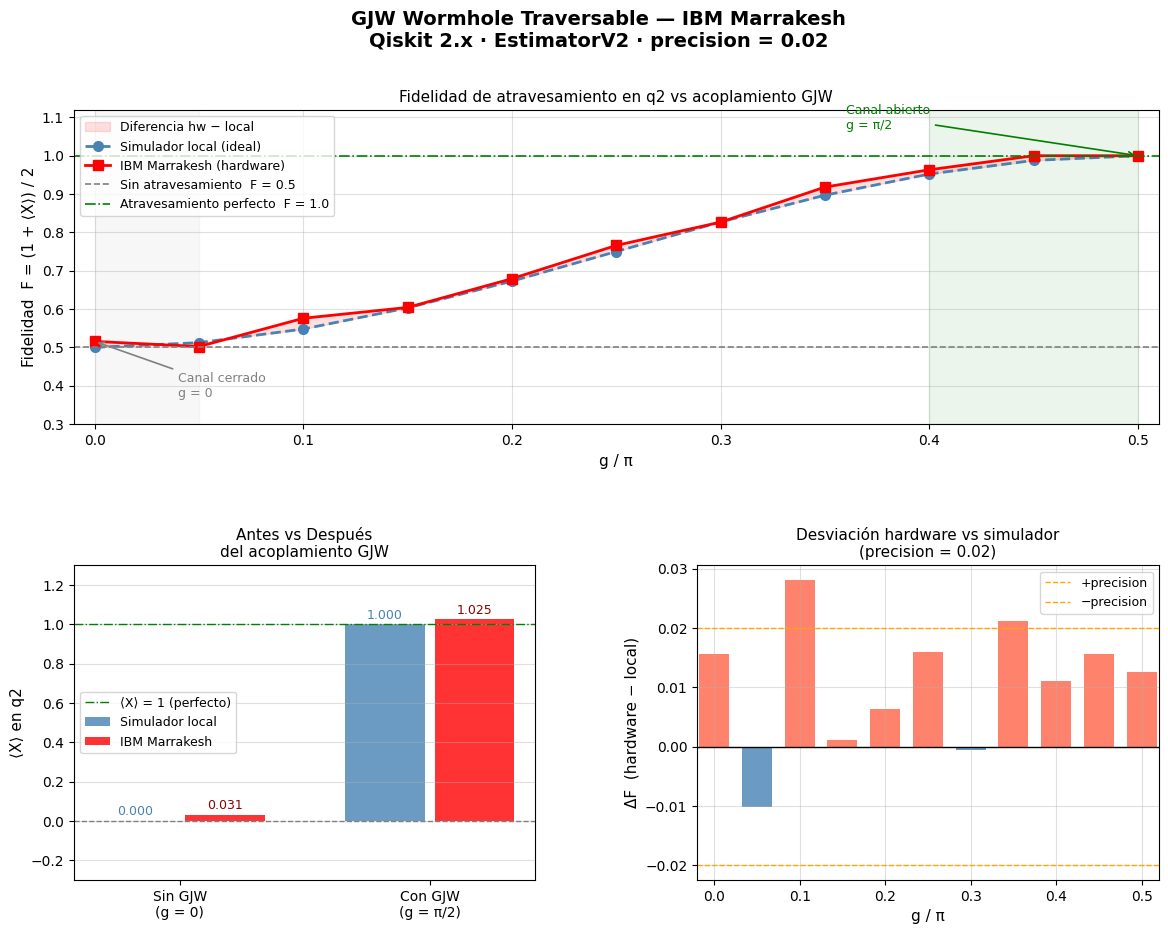

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp, Statevector, state_fidelity, partial_trace
from qiskit_ibm_runtime import QiskitRuntimeService

service   = QiskitRuntimeService(channel="ibm_cloud")
job       = service.job(job.job_id())
status    = job.status()
print("Status:", status)
assert status == "DONE", f"Job no terminado: {status}"

g_values = np.linspace(0, np.pi/2, 11)
psi_in   = Statevector([1/np.sqrt(2), 1/np.sqrt(2)])
g        = Parameter("g")
obs      = SparsePauliOp("IIXII")

qc = QuantumCircuit(5)
qc.h(0);  qc.cx(0, 2)
qc.h(1);  qc.cx(1, 3)
qc.barrier()
qc.h(4)
qc.barrier()
qc.swap(4, 0)
qc.barrier()
qc.rxx(g, 0, 2)
qc.ryy(g, 0, 2)
qc.rzz(g, 0, 2)

fid_local = []
evs_local = []
for gv in g_values:
    sv  = Statevector(qc.assign_parameters([gv]))
    f_x = (1 + sv.expectation_value(obs).real) / 2
    fid_local.append(f_x)
    evs_local.append(2*f_x - 1)

result      = job.result()
evs_hw      = result[0].data.evs.flatten()
fid_hw_raw  = (1 + evs_hw) / 2
fid_hw_clip = np.clip(fid_hw_raw, 0.0, 1.0)
desviacion  = fid_hw_raw - np.array(fid_local)

g_opt_idx = int(np.argmax(fid_hw_clip))

print("\n--- Resultados ---")
print(f"{'g/π':>6}  {'⟨X⟩ hw':>8}  {'F hw':>8}  {'F local':>8}  {'ΔF':>8}")
print("-" * 50)
for gv, ev, fh, fl, d in zip(g_values, evs_hw,
                               fid_hw_raw, fid_local, desviacion):
    print(f"{gv/np.pi:>6.2f}  {ev:>8.4f}  {fh:>8.4f}  {fl:>8.4f}  {d:>8.4f}")

print(f"\nF(g=0)   hardware: {fid_hw_clip[0]:.4f}  (esperado: ~0.5)")
print(f"F(g=π/2) hardware: {fid_hw_clip[-1]:.4f}  (esperado: ~1.0)")
print(f"GJW on > GJW off:  {fid_hw_clip[-1] > fid_hw_clip[0]}")
print(f"Desviación máx:    {max(abs(desviacion)):.4f}")

fig = plt.figure(figsize=(14, 10))
fig.suptitle('GJW Wormhole Traversable — IBM Marrakesh\n'
             'Qiskit 2.x · EstimatorV2 · precision = 0.02',
             fontsize=14, fontweight='bold', y=0.98)

gs = gridspec.GridSpec(2, 2, hspace=0.45, wspace=0.35)

ax1 = fig.add_subplot(gs[0, :])
ax1.fill_between(g_values/np.pi, fid_local, fid_hw_clip,
                 alpha=0.12, color='red', label='Diferencia hw − local')
ax1.plot(g_values/np.pi, fid_local, 'o--', color='steelblue',
         linewidth=2, markersize=7, label='Simulador local (ideal)')
ax1.plot(g_values/np.pi, fid_hw_clip, 's-', color='red',
         linewidth=2, markersize=7, label='IBM Marrakesh (hardware)')
ax1.axhline(0.5, color='gray',  ls='--', linewidth=1.2,
            label='Sin atravesamiento  F = 0.5')
ax1.axhline(1.0, color='green', ls='-.', linewidth=1.2,
            label='Atravesamiento perfecto  F = 1.0')
ax1.axvspan(0.00, 0.05, alpha=0.06, color='gray')
ax1.axvspan(0.40, 0.50, alpha=0.08, color='green')
ax1.annotate('Canal cerrado\ng = 0',
             xy=(0, fid_hw_clip[0]), xytext=(0.04, 0.37),
             fontsize=9, color='gray',
             arrowprops=dict(arrowstyle='->', color='gray', lw=1.2))
ax1.annotate('Canal abierto\ng = π/2',
             xy=(0.5, 1.0), xytext=(0.36, 1.07),
             fontsize=9, color='green',
             arrowprops=dict(arrowstyle='->', color='green', lw=1.2))
ax1.set_xlabel('g / π', fontsize=11)
ax1.set_ylabel('Fidelidad  F = (1 + ⟨X⟩) / 2', fontsize=11)
ax1.set_title('Fidelidad de atravesamiento en q2 vs acoplamiento GJW',
              fontsize=11)
ax1.set_xlim(-0.01, 0.51)
ax1.set_ylim(0.30, 1.12)
ax1.legend(fontsize=9, loc='upper left')
ax1.grid(True, alpha=0.4)

ax2 = fig.add_subplot(gs[1, 0])
x          = np.array([0, 1])
bars_ideal = [evs_local[0],      evs_local[-1]]
bars_hw    = [float(evs_hw[0]),  float(evs_hw[-1])]
b1 = ax2.bar(x - 0.18, bars_ideal, 0.32, color='steelblue',
             alpha=0.8, label='Simulador local')
b2 = ax2.bar(x + 0.18, bars_hw,    0.32, color='red',
             alpha=0.8, label='IBM Marrakesh')
ax2.axhline(0, color='gray',  ls='--', linewidth=1)
ax2.axhline(1, color='green', ls='-.', linewidth=1, label='⟨X⟩ = 1 (perfecto)')
for bar, val in zip(b1, bars_ideal):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.03,
             f'{val:.3f}', ha='center', fontsize=9, color='steelblue')
for bar, val in zip(b2, bars_hw):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.03,
             f'{val:.3f}', ha='center', fontsize=9, color='darkred')
ax2.set_xticks(x)
ax2.set_xticklabels(['Sin GJW\n(g = 0)', 'Con GJW\n(g = π/2)'], fontsize=10)
ax2.set_ylabel('⟨X⟩ en q2', fontsize=11)
ax2.set_title('Antes vs Después\ndel acoplamiento GJW', fontsize=11)
ax2.set_ylim(-0.3, 1.3)
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.4, axis='y')

ax3 = fig.add_subplot(gs[1, 1])
colores = ['tomato' if d > 0 else 'steelblue' for d in desviacion]
ax3.bar(g_values/np.pi, desviacion, width=0.035,
        color=colores, alpha=0.8)
ax3.axhline( 0,    color='black',  linewidth=1)
ax3.axhline( 0.02, color='orange', ls='--', linewidth=1, label='+precision')
ax3.axhline(-0.02, color='orange', ls='--', linewidth=1, label='−precision')
ax3.set_xlabel('g / π', fontsize=11)
ax3.set_ylabel('ΔF  (hardware − local)', fontsize=11)
ax3.set_title('Desviación hardware vs simulador\n(precision = 0.02)',
              fontsize=11)
ax3.set_xlim(-0.02, 0.52)
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.4)

plt.savefig('GJW_resultado_final.png', dpi=150, bbox_inches='tight')
plt.show()
